# 07 — SIFT + bag of visual words + KNN / SVM / Random Forest

Last traditional descriptor: **SIFT** (Scale-Invariant Feature Transform).
SIFT works in two parts:
1. **Detection:** find **keypoints**, small distinctive spots (corners, blobs) with their own size and orientation;
2. **Description:** around each keypoint, a **128-number vector**: 4 × 4 small cells × a histogram of 8 gradient orientations (the same idea as HOG, but local).

**Problem:** every image has a *different number* of keypoints, but a classifier needs *one vector of fixed size* per image.
**Solution: the bag of visual words** (as with words in a text):
- group all the SIFT descriptors into **K families** with *k-means*: each family is a "**visual word**" (a typical small pattern);
- describe each image by **how many times each word appears**: a histogram of K numbers.

The rest is **identical** to notebooks 04-06 (same crops, same 5 video groups, same video decision).

In [1]:
from pathlib import Path
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") / "data" / "raw" / "urfd"
PROC = Path("..") / "data" / "processed"
PHASES = {-1: "not lying", 0: "falling", 1: "lying"}

labels = pd.concat([pd.read_csv(ROOT / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2])
                    for k in ["falls", "adls"]], ignore_index=True)
labels.columns = ["video", "frame", "frame_label"]

z = np.load(PROC / "crops64.npz")          # the 64 x 64 person crops made in notebook 04
frames = pd.DataFrame({"video": z["video"], "frame": z["frame"]}).merge(labels, on=["video", "frame"], how="left")
keep = frames.frame_label.notna().to_numpy()
crops, frames = z["crops"][keep], frames[keep].reset_index(drop=True)
frames["phase"] = frames.frame_label.map(PHASES)
gray = np.stack([cv2.cvtColor(c, cv2.COLOR_RGB2GRAY) for c in crops])   # SIFT works on grey levels
y = frames.frame_label.astype(int).to_numpy()
print(gray.shape)

(11027, 64, 64)


💡 **Interpretation:** the same **11,027 crops** as notebooks 04-06, in grey levels (64 × 64), because SIFT uses gradients of brightness only.

## Step 1 — SIFT keypoints on the crops

Each circle is a keypoint: its **size** is the scale where SIFT found it, the **line** is its main orientation.

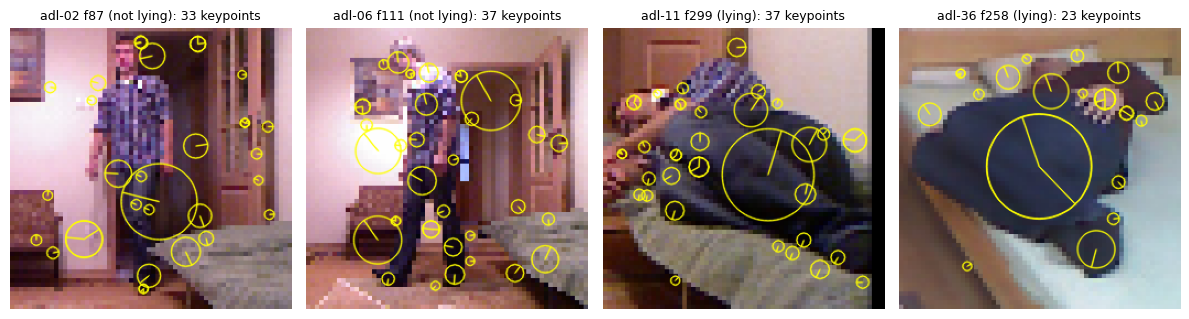

keypoints per crop: median 25, min 0, max 68, crops with none: 56


In [2]:
sift = cv2.SIFT_create()
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, phase, n in zip(axes, ["not lying", "not lying", "lying", "lying"], [200, 900, 200, 900]):
    i = frames[frames.phase == phase].index[n]
    big = cv2.resize(crops[i], (256, 256), interpolation=cv2.INTER_NEAREST)   # bigger, only to draw clearly
    keypoints = sift.detect(gray[i], None)
    for k in keypoints:
        k.pt, k.size = (k.pt[0] * 4, k.pt[1] * 4), k.size * 4
    ax.imshow(cv2.drawKeypoints(big, keypoints, None, color=(255, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS))
    ax.set_title(f"{frames.video[i]} f{frames.frame[i]} ({phase}): {len(keypoints)} keypoints", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

counts = np.array([len(sift.detect(g, None)) for g in gray])
print(f"keypoints per crop: median {np.median(counts):.0f}, min {counts.min()}, max {counts.max()}, crops with none: {np.sum(counts == 0)}")

💡 **Interpretation:** about **25 keypoints per crop** (56 crops have none). Many fall on the **background** (door, picture frame, bed cover), not on the body,
and their positions change from frame to frame: on such small crops the detector picks whatever corners are there.

## Step 2 — Two ways to place the SIFT descriptors

- **Detected SIFT** (the classic one): descriptors only at the keypoints SIFT finds (step 1).
- **Dense SIFT**: descriptors on a **regular grid**: every 8 pixels, a 16-pixel patch → 7 × 7 = **49 descriptors per crop**, always at the same places.
  Dense SIFT is often used for classification of small images, because it covers the whole image, not only the corners.

Each descriptor has **128 numbers** in both cases.

In [3]:
t = time.time()
detected = []
for g in gray:
    _, d = sift.detectAndCompute(g, None)
    detected.append(d if d is not None else np.zeros((0, 128), np.float32))

grid = [cv2.KeyPoint(float(x), float(yy), 16) for yy in range(8, 64, 8) for x in range(8, 64, 8)]
dense = [sift.compute(g, grid)[1] for g in gray]
print(f"detected: {sum(len(d) for d in detected):,} descriptors, dense: {sum(len(d) for d in dense):,} descriptors "
      f"of {dense[0].shape[1]} numbers, in {time.time() - t:.0f} s")

detected: 257,909 descriptors, dense: 540,323 descriptors of 128 numbers, in 22 s


💡 **Interpretation:** 258,000 detected descriptors (about 23 per crop, varying) vs 540,000 dense ones (always **49 per crop**), each of **128 numbers**, computed in about 20 s.

## Step 3 — The same fair test (split by video), and a fair vocabulary

Same 5 groups of 14 videos as before. One more rule here: the **vocabulary** (k-means) is learnt **only from the training videos** of each round.
Otherwise the test images would have helped to build the words, a small leak of information.

So we cannot simply call `cross_val_predict`; we write the 5 rounds ourselves:
1. take 100,000 descriptors from the training videos and run k-means → **K visual words**;
2. replace every descriptor of every crop by the number of its nearest word;
3. histogram of the words for each crop (divided by its total, so it adds up to 1);
4. train the classifiers on the training videos, predict the test videos.

In [4]:
from sklearn.model_selection import StratifiedKFold
from sklearn.cluster import MiniBatchKMeans

videos = np.array(sorted(frames.video.unique()))
is_fall = np.char.startswith(videos, "fall").astype(int)
fold_of = {}
for k, (_, test) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(videos, is_fall)):
    fold_of.update({v: k for v in videos[test]})
frames["fold"] = frames.video.map(fold_of)

def bag_of_words(descriptors, train, K):
    sample = np.vstack([descriptors[i] for i in np.flatnonzero(train)])
    sample = sample[np.random.default_rng(0).choice(len(sample), min(100_000, len(sample)), replace=False)]
    vocabulary = MiniBatchKMeans(n_clusters=K, n_init=3, batch_size=4096, random_state=0).fit(sample)
    H = np.stack([np.bincount(vocabulary.predict(d), minlength=K) if len(d) else np.zeros(K) for d in descriptors])
    return H / np.maximum(H.sum(axis=1, keepdims=True), 1)

def evaluate(descriptors, classifiers, K=300):
    pred = {name: np.zeros_like(y) for name in classifiers}
    for f in range(5):
        train, test = frames.fold.to_numpy() != f, frames.fold.to_numpy() == f
        H = bag_of_words(descriptors, train, K)
        for name, clf in classifiers.items():
            pred[name][test] = clf.fit(H[train], y[train]).predict(H[test])
    return pred

frames.groupby("fold").agg(videos=("video", "nunique"), frames=("video", "size"))

,videos,frames
fold,,
0,14,2175
1,14,2321
2,14,2227
3,14,2044
4,14,2260


💡 **Interpretation:** the same 5 groups of **14 videos** as before; in each round the visual words are learnt only from the 56 training videos.

## Step 4 — Detected or dense SIFT?

Comparison with a vocabulary of **K = 300 words**, using KNN and SVM.

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

rows = []
for name, descriptors in [("detected SIFT", detected), ("dense SIFT", dense)]:
    pred = evaluate(descriptors, {"KNN": KNeighborsClassifier(n_neighbors=5), "SVM": SVC(kernel="rbf")})
    for clf, p in pred.items():
        rows.append({"SIFT": name, "classifier": clf, "frame accuracy": accuracy_score(y, p), "macro F1": f1_score(y, p, average="macro")})
pd.DataFrame(rows).round(3)

,SIFT,classifier,frame accuracy,macro F1
0,detected SIFT,KNN,0.649,0.339
1,detected SIFT,SVM,0.751,0.622
2,dense SIFT,KNN,0.839,0.771
3,dense SIFT,SVM,0.866,0.799


💡 **Interpretation:** **detected SIFT is weak** (SVM 0.751, KNN 0.649, barely above always saying *not lying*: 0.640): too few keypoints, often on the background.
**Dense SIFT is much better** (SVM **0.866**), because it describes the whole crop. We keep dense SIFT.

## Step 5 — How many visual words?

A small vocabulary mixes different patterns in one word; a big one separates them better but needs more data. We compare K = 100, 300 and 500 with the SVM on dense SIFT.

In [6]:
rows = []
for K in [100, 300, 500]:
    t = time.time()
    p = evaluate(dense, {"SVM": SVC(kernel="rbf")}, K=K)["SVM"]
    rows.append({"K (visual words)": K, "frame accuracy": accuracy_score(y, p), "macro F1": f1_score(y, p, average="macro"),
                 "time (s)": time.time() - t})
pd.DataFrame(rows).round(3)

,K (visual words),frame accuracy,macro F1,time (s)
0,100,0.847,0.761,19.126
1,300,0.866,0.799,43.717
2,500,0.865,0.804,74.779


💡 **Interpretation:** 100 words is too few (0.847); **300 and 500 are equal** (0.866 vs 0.865) but 500 is slower, so we keep **K = 300**.

## Step 6 — Three classifiers on dense SIFT, K = 300

In [7]:
from sklearn.ensemble import RandomForestClassifier

classifiers = {"KNN": KNeighborsClassifier(n_neighbors=5),
               "SVM": SVC(kernel="rbf"),
               "RF": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)}
t = time.time()
pred = evaluate(dense, classifiers, K=300)
frame_scores = pd.DataFrame([{"classifier": name, "frame accuracy": accuracy_score(y, p), "macro F1": f1_score(y, p, average="macro")}
                             for name, p in pred.items()]).round(3)
print(f"{time.time() - t:.0f} s for the 5 rounds")
frame_scores

49 s for the 5 rounds


,classifier,frame accuracy,macro F1
0,KNN,0.839,0.771
1,SVM,0.866,0.799
2,RF,0.858,0.790


💡 **Interpretation:** **SVM is best** (0.866, macro F1 0.799), RF close (0.858), KNN behind (0.839): word histograms suit the SVM better than distances between neighbours.
On frames, dense SIFT is at the level of HOG (0.859) and LBP (0.867), below colour (0.896).

## Step 7 — Which postures are confused? (best classifier)

best: SVM
              precision    recall  f1-score   support

   not lying       0.92      0.94      0.93      7054
     falling       0.62      0.63      0.63      1717
       lying       0.88      0.80      0.84      2256

    accuracy                           0.87     11027
   macro avg       0.81      0.79      0.80     11027
weighted avg       0.87      0.87      0.87     11027



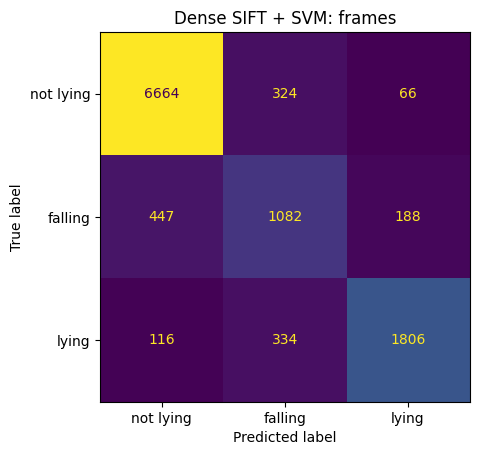

In [8]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best = frame_scores.sort_values("macro F1").classifier.iloc[-1]
names = [PHASES[k] for k in (-1, 0, 1)]
print("best:", best)
print(classification_report(y, pred[best], target_names=names))
ConfusionMatrixDisplay.from_predictions(y, pred[best], display_labels=names, colorbar=False)
plt.title(f"Dense SIFT + {best}: frames"); plt.show()

💡 **Interpretation:** same pattern as the other descriptors: *not lying* easy (F1 0.93), *lying* good (0.84), *falling* hardest (**0.63**, the lowest of the 4 descriptors).
Bag of words throws away **where** each word is in the crop, and that layout is what separates the posture phases.

## Step 8 — From frames to the whole video: fall or no fall?

Same decision as notebooks 04-06: the **share** of each video's frames in each posture → logistic regression, same 5 video groups.

In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score

def video_decision(frame_pred):
    share = pd.crosstab(frames.video, frame_pred, normalize="index").reindex(columns=[-1, 0, 1], fill_value=0)
    share.columns = ["share not lying", "share falling", "share lying"]
    y_video = share.index.str.startswith("fall").astype(int)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    video_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    return share, y_video, cross_val_predict(model, share, y_video, cv=video_cv)

rows, video_pred = [], {}
for name in classifiers:
    share, y_video, video_pred[name] = video_decision(pred[name])
    rows.append({"classifier": name, "video accuracy": accuracy_score(y_video, video_pred[name]),
                 "recall (falls)": recall_score(y_video, video_pred[name]),
                 "precision (falls)": precision_score(y_video, video_pred[name])})
video_scores = pd.DataFrame(rows).round(3)
share, y_video, _ = video_decision(pred[best])
print(share.groupby(y_video).mean().rename(index={0: "ADL videos", 1: "fall videos"}).round(2))
video_scores

             share not lying  share falling  share lying
ADL videos              0.79           0.10         0.12
fall videos             0.41           0.29         0.30


,classifier,video accuracy,recall (falls),precision (falls)
0,KNN,0.757,0.667,0.741
1,SVM,0.743,0.667,0.714
2,RF,0.786,0.733,0.759


💡 **Interpretation:** ADL videos get **10%** of frames predicted *falling* (HOG: 5%), so the decision is less clean: video accuracy **0.743-0.786**, the weakest of the 4 descriptors.

## Step 9 — Which videos are wrong?

In [10]:
length = labels.groupby("video").size()
wrong_videos = share.index[video_pred[best] != y_video]
print(f"Dense SIFT + {best}: {len(wrong_videos)} wrong videos")
print(pd.DataFrame({"frames in video": length[wrong_videos], "share lying": share.loc[wrong_videos, "share lying"].round(2),
                    "share falling": share.loc[wrong_videos, "share falling"].round(2)}))
hog_wrong = {"fall-01", "fall-03", "fall-05", "fall-07", "fall-09", "adl-31", "adl-32", "adl-33", "adl-34", "adl-35"}  # notebook 04
print("\nalso wrong with HOG + KNN:", sorted(hog_wrong & set(wrong_videos)))

Dense SIFT + SVM: 18 wrong videos
         frames in video  share lying  share falling
video                                               
adl-30               369         0.36           0.17
adl-31               250         0.38           0.40
adl-32               200         0.36           0.22
adl-34               191         0.34           0.34
adl-35               280         0.28           0.50
adl-36               323         0.02           0.47
adl-38               327         0.43           0.19
adl-40               286         0.24           0.25
fall-01              160         0.32           0.11
fall-02              110         0.44           0.11
fall-03              215         0.17           0.11
fall-05              151         0.30           0.12
fall-07              156         0.04           0.31
fall-09              185         0.22           0.11
fall-13               85         0.18           0.26
fall-21               55         0.04           0.33
fall-27     

💡 **Interpretation:** **18 wrong videos**: 9 of the 10 HOG errors (long falls, lying down on purpose) plus more ADLs where someone goes to the floor (adl-30, 36, 38, 40)
and short falls with few *lying* frames (fall-21: 4%, fall-07: 4%).

## Step 10 — Save the scores for the benchmark (notebook 08)

In [11]:
RESULTS = PROC / "results_traditional.csv"
scores = frame_scores.merge(video_scores, on="classifier")
scores.insert(0, "descriptor", "SIFT (dense, BoVW)")
old = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame()
if len(old):
    old = old[old.descriptor != "SIFT (dense, BoVW)"]
table = pd.concat([old, scores], ignore_index=True)
table.to_csv(RESULTS, index=False)
table

,descriptor,classifier,frame accuracy,macro F1,video accuracy,recall (falls),precision (falls)
0,HOG,KNN,0.859,0.799,0.857,0.833,0.833
1,HOG,SVM,0.859,0.795,0.800,0.733,0.786
2,HOG,RF,0.855,0.770,0.829,0.767,0.821
3,LBP,KNN,0.867,0.816,0.771,0.767,0.719
4,LBP,SVM,0.873,0.810,0.757,0.733,0.710
5,LBP,RF,0.866,0.796,0.786,0.733,0.759
6,Colour (HSV),KNN,0.883,0.834,0.800,0.767,0.767
7,Colour (HSV),SVM,0.886,0.834,0.843,0.833,0.806
8,Colour (HSV),RF,0.896,0.842,0.800,0.767,0.767
9,"SIFT (dense, BoVW)",KNN,0.839,0.771,0.757,0.667,0.741


💡 **Interpretation:** the traditional part is complete: **12 rows** (4 descriptors × 3 classifiers). Notebook 08 compares them all.

## What we learned

1. **SIFT** = keypoints + a 128-number descriptor around each; the **bag of visual words** (k-means vocabulary, histogram of words) turns a varying number of descriptors into one fixed vector.
2. **Detected SIFT fails on our small crops** (0.751): about 25 keypoints, many on the background. **Dense SIFT** (49 descriptors on a grid) works much better (0.866).
3. **300 visual words** are enough (500 gives the same), and the **SVM** is the best classifier here.
4. On frames, dense SIFT is **at the level of HOG and LBP** (0.866), but it gives the **weakest video decision** (0.743-0.786) and the worst *falling* class (F1 0.63): the bag of words forgets *where* each pattern is.
5. **Fair test:** the vocabulary is learnt only on the training videos of each round, so the test videos never help to build it.

**Next notebook (08):** the **benchmark of the traditional part**: all descriptors and classifiers side by side, at frame and video level, to choose the best traditional method.